# Melbourne Weather: Data Acquisition

This notebook retrieves and validates historical weather data for 2025 for use in analysing the relationship between weather conditions and Victorian electricity demand.

## 1. Setup

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openmeteo_requests
import requests_cache

from pathlib import Path
from retry_requests import retry

PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

## 2. Retrieve Historical Weather Data

Historical weather data is retrieved for Melbourne and used as a proxy for weather conditions affecting Victorian electricity demand. Temperature and other weather variables will later be aligned with the 30-minute electricity demand observations.

Melbourne weather is an imperfect proxy for conditions across Victoria, which is considered a limitation of the analysis.

In [44]:
cache_session = requests_cache.CachedSession(
    ".cache",
    expire_after=-1
)

retry_session = retry(
    cache_session,
    retries=5,
    backoff_factor=0.2
)

openmeteo = openmeteo_requests.Client(
    session=retry_session
)

In [45]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": -37.8136,
    "longitude": 144.9631,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "apparent_temperature",
        "precipitation",
        "wind_speed_10m"
    ],
    "timezone": "Australia/Melbourne"
}

responses = openmeteo.weather_api(
    url,
    params=params
)

response = responses[0]

print("Latitude:", response.Latitude())
print("Longitude:", response.Longitude())
print("Elevation:", response.Elevation())

Latitude: -37.785587310791016
Longitude: 144.93975830078125
Elevation: 19.0


## 3. Build Weather Dataset

In [46]:
hourly = response.Hourly()

weather = pd.DataFrame({
    "datetime": pd.date_range(
        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=hourly.Interval()),
        inclusive="left"
    ),
    "temperature_c": hourly.Variables(0).ValuesAsNumpy(),
    "relative_humidity": hourly.Variables(1).ValuesAsNumpy(),
    "apparent_temperature_c": hourly.Variables(2).ValuesAsNumpy(),
    "precipitation_mm": hourly.Variables(3).ValuesAsNumpy(),
    "wind_speed_kmh": hourly.Variables(4).ValuesAsNumpy()
})

display(weather.head())

print("\nShape:", weather.shape)

,datetime,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh
0,2024-12-31 14:00:00+00:00,16.650000,76.249390,16.708132,0.0,4.863332
1,2024-12-31 15:00:00+00:00,16.200001,80.284676,16.560896,0.0,3.586474
2,2024-12-31 16:00:00+00:00,15.750000,83.439499,16.217306,0.0,3.204809
3,2024-12-31 17:00:00+00:00,15.400000,85.052567,15.771622,0.0,3.745557
4,2024-12-31 18:00:00+00:00,14.950000,86.408943,14.887655,0.0,6.261310



Shape: (8760, 6)


In [47]:
print(weather["datetime"].head())
print(weather["datetime"].tail())
print(weather["datetime"].dtype)

0   2024-12-31 14:00:00+00:00
1   2024-12-31 15:00:00+00:00
2   2024-12-31 16:00:00+00:00
3   2024-12-31 17:00:00+00:00
4   2024-12-31 18:00:00+00:00
Name: datetime, dtype: datetime64[s, UTC]
8755   2025-12-31 09:00:00+00:00
8756   2025-12-31 10:00:00+00:00
8757   2025-12-31 11:00:00+00:00
8758   2025-12-31 12:00:00+00:00
8759   2025-12-31 13:00:00+00:00
Name: datetime, dtype: datetime64[s, UTC]
datetime64[s, UTC]


## 4. Align Weather Timestamps to AEMO Market Time

AEMO settlement timestamps use Australian Eastern Standard Time (AEST, UTC+10) throughout the year. Weather timestamps are therefore converted from UTC to fixed AEST before they are aligned with electricity demand.

In [48]:
weather["datetime_aest"] = (
    weather["datetime"]
    .dt.tz_convert("Australia/Brisbane")
    .dt.tz_localize(None)
)

display(
    weather[["datetime", "datetime_aest"]].head()
)

display(
    weather[["datetime", "datetime_aest"]].tail()
)

,datetime,datetime_aest
0,2024-12-31 14:00:00+00:00,2025-01-01 00:00:00
1,2024-12-31 15:00:00+00:00,2025-01-01 01:00:00
2,2024-12-31 16:00:00+00:00,2025-01-01 02:00:00
3,2024-12-31 17:00:00+00:00,2025-01-01 03:00:00
4,2024-12-31 18:00:00+00:00,2025-01-01 04:00:00


,datetime,datetime_aest
8755,2025-12-31 09:00:00+00:00,2025-12-31 19:00:00
8756,2025-12-31 10:00:00+00:00,2025-12-31 20:00:00
8757,2025-12-31 11:00:00+00:00,2025-12-31 21:00:00
8758,2025-12-31 12:00:00+00:00,2025-12-31 22:00:00
8759,2025-12-31 13:00:00+00:00,2025-12-31 23:00:00


In [49]:
weather = (
    weather
    .drop(columns="datetime")
    .rename(columns={"datetime_aest": "datetime"})
)

weather = weather[
    (weather["datetime"] >= "2025-01-01 00:00:00") &
    (weather["datetime"] < "2026-01-01 00:00:00")
].copy()

weather = weather.sort_values("datetime").reset_index(drop=True)

print("Shape:", weather.shape)
print("Start:", weather["datetime"].min())
print("End:", weather["datetime"].max())

display(weather.head())

Shape: (8760, 6)
Start: 2025-01-01 00:00:00
End: 2025-12-31 23:00:00


,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh,datetime
0,16.650000,76.249390,16.708132,0.0,4.863332,2025-01-01 00:00:00
1,16.200001,80.284676,16.560896,0.0,3.586474,2025-01-01 01:00:00
2,15.750000,83.439499,16.217306,0.0,3.204809,2025-01-01 02:00:00
3,15.400000,85.052567,15.771622,0.0,3.745557,2025-01-01 03:00:00
4,14.950000,86.408943,14.887655,0.0,6.261310,2025-01-01 04:00:00


## 5. Validate Weather Data

In [50]:
print("Missing values:")
print(weather.isna().sum())

print("\nDuplicate timestamps:")
print(weather["datetime"].duplicated().sum())

print("\nWeather summary:")
display(
    weather[
        [
            "temperature_c",
            "relative_humidity",
            "apparent_temperature_c",
            "precipitation_mm",
            "wind_speed_kmh"
        ]
    ].describe().round(2)
)

Missing values:
temperature_c             0
relative_humidity         0
apparent_temperature_c    0
precipitation_mm          0
wind_speed_kmh            0
datetime                  0
dtype: int64

Duplicate timestamps:
0

Weather summary:


,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh
count,8760.00,8760.00,8760.00,8760.00,8760.00
mean,15.29,68.04,13.60,0.09,11.06
std,6.06,17.53,6.87,0.44,6.30
min,1.80,7.57,-0.50,0.00,0.00
25%,11.00,56.32,8.46,0.00,5.94
50%,14.40,70.62,12.55,0.00,10.48
75%,18.60,81.14,17.49,0.00,15.23
max,40.65,100.00,40.02,11.50,39.48


In [51]:
weather_gaps = (
    weather["datetime"]
    .diff()
    .value_counts()
    .sort_index()
)

display(weather_gaps)

datetime
0 days 01:00:00    8759
Name: count, dtype: int64

## 6. Inspect Weather During Extreme Demand Periods

Examine weather conditions during the February dates associated with the highest Victorian electricity demand observations.

In [52]:
feb_peak_weather = weather[
    (weather["datetime"] >= "2025-02-02") &
    (weather["datetime"] < "2025-02-04")
]

display(feb_peak_weather)

,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh,datetime
768,23.650000,65.272087,25.558468,0.0,3.148714,2025-02-02 00:00:00
769,23.150000,66.422180,24.888298,0.0,3.745557,2025-02-02 01:00:00
770,22.950001,66.592377,24.668392,0.0,3.457687,2025-02-02 02:00:00
771,22.650000,65.896568,24.074757,0.0,4.217535,2025-02-02 03:00:00
772,23.750000,53.686382,23.916353,0.0,7.264957,2025-02-02 04:00:00
773,25.700001,41.370323,24.299580,0.0,12.961250,2025-02-02 05:00:00
774,25.950001,42.406158,24.181629,0.0,16.794106,2025-02-02 06:00:00
775,26.799999,42.087940,25.063438,0.0,18.044046,2025-02-02 07:00:00
776,28.400000,39.087063,26.589209,0.0,19.242327,2025-02-02 08:00:00
777,30.500000,35.541622,28.582214,0.0,20.912560,2025-02-02 09:00:00


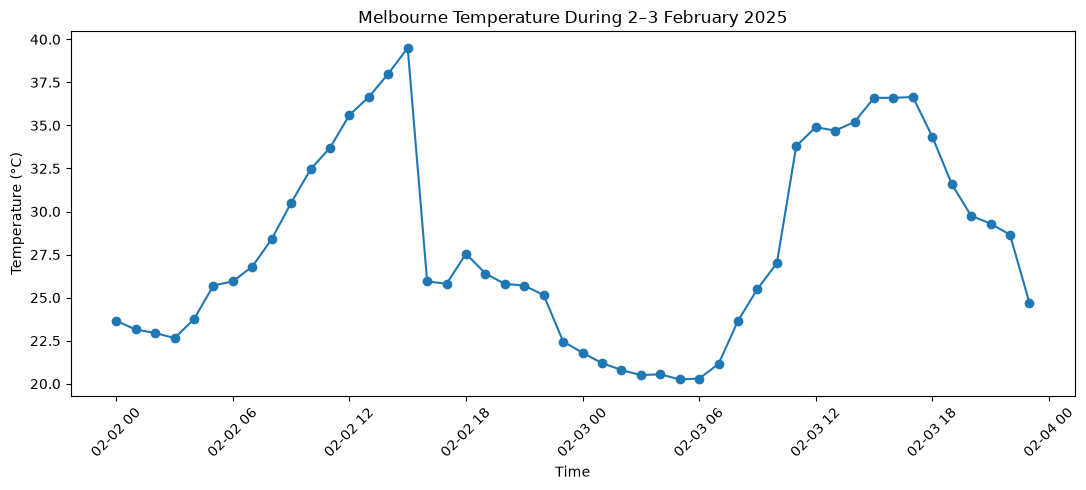

In [53]:
plt.figure(figsize=(11, 5))

plt.plot(
    feb_peak_weather["datetime"],
    feb_peak_weather["temperature_c"],
    marker="o"
)

plt.title("Melbourne Temperature During 2–3 February 2025")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 7. Convert Weather to 30 Minute Resolution

Interpolate hourly weather observations to 30-minute intervals so they can be aligned with the electricity demand dataset.

In [54]:
weather_30min = (
    weather
    .set_index("datetime")
    .resample("30min")
    .interpolate(method="time")
    .reset_index()
)

print("Shape:", weather_30min.shape)
print("Start:", weather_30min["datetime"].min())
print("End:", weather_30min["datetime"].max())

display(weather_30min.head(10))

Shape: (17519, 6)
Start: 2025-01-01 00:00:00
End: 2025-12-31 23:00:00


,datetime,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh
0,2025-01-01 00:00:00,16.650000,76.249390,16.708132,0.0,4.863332
1,2025-01-01 00:30:00,16.424999,78.267029,16.634514,0.0,4.224903
2,2025-01-01 01:00:00,16.200001,80.284676,16.560896,0.0,3.586474
3,2025-01-01 01:30:00,15.975000,81.862091,16.389101,0.0,3.395642
4,2025-01-01 02:00:00,15.750000,83.439499,16.217306,0.0,3.204809
5,2025-01-01 02:30:00,15.575000,84.246033,15.994464,0.0,3.475183
6,2025-01-01 03:00:00,15.400000,85.052567,15.771622,0.0,3.745557
7,2025-01-01 03:30:00,15.174999,85.730759,15.329638,0.0,5.003433
8,2025-01-01 04:00:00,14.950000,86.408943,14.887655,0.0,6.261310
9,2025-01-01 04:30:00,14.799999,86.111458,14.546976,0.0,7.116141


In [55]:
print("Missing values:")
print(weather_30min.isna().sum())

print("\nDuplicate timestamps:")
print(weather_30min["datetime"].duplicated().sum())

print("\nTime gaps:")
print(
    weather_30min["datetime"]
    .diff()
    .value_counts()
    .sort_index()
)

Missing values:
datetime                  0
temperature_c             0
relative_humidity         0
apparent_temperature_c    0
precipitation_mm          0
wind_speed_kmh            0
dtype: int64

Duplicate timestamps:
0

Time gaps:
datetime
0 days 00:30:00    17518
Name: count, dtype: int64


## 8. Save Processed Weather Data

In [56]:
weather_path = PROCESSED_DATA_DIR / "melbourne_weather_2025_30min.parquet"

weather_30min.to_parquet(
    weather_path,
    index=False
)

print(f"Saved to: {weather_path}")

Saved to: /Users/mani/Desktop/Projects/victorian-electricity-demand/data/processed/melbourne_weather_2025_30min.parquet
